# PathSnap — HMM & Viterbi Route Reconstruction
**P3 Development Notebook**

This notebook covers:
1. Data loading & understanding
2. Road network graph construction
3. Candidate arc generation
4. HMM emission & transition probabilities
5. Viterbi decoding
6. Evaluation against ground truth
7. Parameter tuning
8. Folium visualizations

In [1]:
import numpy as np
import pandas as pd
import networkx as nx
import folium
import os
import time
from math import radians, sin, cos, sqrt, atan2
from collections import defaultdict

In [2]:
# === PATHS — update if needed ===
BASE = r"C:\Users\Hnk\Desktop\pes3rd\ML\hackathon\Student folder\Student folder"
TRAIN_DIR = os.path.join(BASE, "train")
TEST_DIR = os.path.join(BASE, "student_test")

## 1. Data Loading

In [3]:
def load_trip(trip_dir, trip_id):
    prefix = os.path.join(trip_dir, trip_id)
    trip = {
        "trip_id": trip_id,
        "track": np.loadtxt(f"{prefix}.track"),    # (N,3): lon, lat, timestamp
        "nodes": np.loadtxt(f"{prefix}.nodes"),    # (M,2): lon, lat
        "arcs": np.loadtxt(f"{prefix}.arcs", dtype=int),  # (A,2): from_node, to_node
    }
    route_path = f"{prefix}.route"
    trip["route"] = np.loadtxt(route_path, dtype=int) if os.path.exists(route_path) else None
    return trip

In [4]:
# Load a sample trip
trip = load_trip(os.path.join(TRAIN_DIR, "00000001"), "00000001")

print(f"Track (GPS points):  {trip['track'].shape}  — columns: lon, lat, timestamp")
print(f"Nodes (road junctions): {trip['nodes'].shape}  — columns: lon, lat")
print(f"Arcs (road segments):  {trip['arcs'].shape}  — columns: from_node_id, to_node_id")
print(f"Route (ground truth):  {trip['route'].shape}  — sequence of arc_ids")
print()
print("First 5 GPS points:")
print(trip['track'][:5])
print("\nFirst 5 ground truth arcs:", trip['route'][:5])

Track (GPS points):  (1315, 3)  — columns: lon, lat, timestamp
Nodes (road junctions): (88809, 2)  — columns: lon, lat
Arcs (road segments):  (165790, 2)  — columns: from_node_id, to_node_id
Route (ground truth):  (525,)  — sequence of arc_ids

First 5 GPS points:
[[ 8.595203 49.844053  1.      ]
 [ 8.595294 49.844441  2.      ]
 [ 8.595352 49.844883  3.      ]
 [ 8.59539  49.845379  4.      ]
 [ 8.595587 49.84575   5.      ]]

First 5 ground truth arcs: [  2641  64973 133948 133949 139208]


## 2. Helper Functions

In [5]:
def haversine(lon1, lat1, lon2, lat2):
    """Distance in meters between two (lon,lat) points."""
    R = 6371000
    lon1, lat1, lon2, lat2 = map(radians, [lon1, lat1, lon2, lat2])
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = sin(dlat/2)**2 + cos(lat1)*cos(lat2)*sin(dlon/2)**2
    return R * 2 * atan2(sqrt(a), sqrt(1-a))


def haversine_vec(lon1, lat1, lon2, lat2):
    """Vectorized haversine for arrays."""
    R = 6371000
    lon1, lat1, lon2, lat2 = [np.radians(x) for x in [lon1, lat1, lon2, lat2]]
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat/2)**2 + np.cos(lat1)*np.cos(lat2)*np.sin(dlon/2)**2
    return R * 2 * np.arctan2(np.sqrt(a), np.sqrt(1-a))


def point_to_segment_distance(px, py, ax, ay, bx, by):
    """Distance from point (px,py) to segment (ax,ay)-(bx,by). Returns (meters, t)."""
    dx, dy = bx - ax, by - ay
    if dx == 0 and dy == 0:
        return haversine(px, py, ax, ay), 0.0
    t = max(0.0, min(1.0, ((px-ax)*dx + (py-ay)*dy) / (dx*dx + dy*dy)))
    proj_lon = ax + t*dx
    proj_lat = ay + t*dy
    return haversine(px, py, proj_lon, proj_lat), t

## 3. Road Network Graph

In [6]:
def build_graph(nodes, arcs):
    """Build directed graph. Edges store arc_id and length."""
    G = nx.DiGraph()
    for nid in range(len(nodes)):
        G.add_node(nid, lon=nodes[nid, 0], lat=nodes[nid, 1])
    for aid in range(len(arcs)):
        fn, tn = arcs[aid]
        length = haversine(nodes[fn,0], nodes[fn,1], nodes[tn,0], nodes[tn,1])
        G.add_edge(fn, tn, arc_id=aid, length=length)
    return G

In [7]:
t0 = time.time()
graph = build_graph(trip["nodes"], trip["arcs"])
print(f"Graph: {graph.number_of_nodes()} nodes, {graph.number_of_edges()} edges — built in {time.time()-t0:.1f}s")

Graph: 88809 nodes, 165498 edges — built in 1.2s


## 4. Candidate Generation
For each GPS point, find the K nearest road arcs.

In [8]:
def build_arc_midpoints(nodes, arcs):
    """Midpoint of each arc for spatial pre-filter."""
    return (nodes[arcs[:, 0]] + nodes[arcs[:, 1]]) / 2.0


def find_candidates(gps_lon, gps_lat, nodes, arcs, midpoints, k=10, radius_m=300):
    """Find k nearest arcs to a GPS point. Returns [(arc_id, dist_m, proj_t), ...]"""
    # Pre-filter by midpoint distance
    mid_dists = haversine_vec(gps_lon, gps_lat, midpoints[:, 0], midpoints[:, 1])
    pre_k = min(k * 3, len(arcs))
    top_indices = np.argpartition(mid_dists, pre_k)[:pre_k]
    
    # Exact point-to-segment distance
    results = []
    for aid in top_indices:
        fn, tn = arcs[aid]
        dist, t = point_to_segment_distance(
            gps_lon, gps_lat, nodes[fn,0], nodes[fn,1], nodes[tn,0], nodes[tn,1]
        )
        results.append((int(aid), dist, t))
    
    results.sort(key=lambda x: x[1])
    results = [r for r in results[:k] if r[1] <= radius_m]
    if not results:
        results = [min([(int(aid), haversine(gps_lon, gps_lat, midpoints[aid,0], midpoints[aid,1]), 0.5) 
                        for aid in top_indices], key=lambda x: x[1])]
    return results


def generate_all_candidates(track, nodes, arcs, k=10, radius_m=300):
    midpoints = build_arc_midpoints(nodes, arcs)
    return [find_candidates(track[i,0], track[i,1], nodes, arcs, midpoints, k, radius_m)
            for i in range(len(track))]

In [9]:
# Generate candidates for all GPS points
t0 = time.time()
candidates = generate_all_candidates(trip["track"], trip["nodes"], trip["arcs"], k=10, radius_m=300)
print(f"Candidates generated for {len(candidates)} GPS points in {time.time()-t0:.1f}s")

# Check how often ground truth is in candidate set
route = trip["route"]
hits = sum(1 for i in range(min(len(candidates), len(route)))
           if route[i] in [c[0] for c in candidates[i]])
total = min(len(candidates), len(route))
print(f"Ground truth in candidates: {hits}/{total} ({100*hits/total:.1f}%)")
print(f"Avg candidates per point: {np.mean([len(c) for c in candidates]):.1f}")

Candidates generated for 1315 GPS points in 23.6s
Ground truth in candidates: 6/525 (1.1%)
Avg candidates per point: 10.0


## 5. HMM Components

**Hidden states:** candidate road arcs for each GPS observation  
**Emissions:** how likely a GPS point is given a road arc (Gaussian on distance)  
**Transitions:** how likely moving from one arc to the next (exponential on route vs. straight-line distance)

In [10]:
def emission_prob(distance_m, sigma=50.0):
    """P(GPS obs | road arc). Gaussian on distance. sigma = GPS noise in meters."""
    return (1.0 / (sigma * np.sqrt(2*np.pi))) * np.exp(-0.5 * (distance_m/sigma)**2)


def transition_prob(route_dist, gc_dist, beta=20.0):
    """P(arc_t | arc_{t-1}). Exponential on |route_dist - great_circle_dist|."""
    dt = abs(route_dist - gc_dist)
    return (1.0 / beta) * np.exp(-dt / beta)


def route_distance(arc_from, arc_to, arcs, graph, max_hops=8):
    """Shortest path distance between end of arc_from and start of arc_to."""
    end_node = arcs[arc_from][1]
    start_node = arcs[arc_to][0]
    if end_node == start_node or arc_from == arc_to:
        return 0.0
    try:
        path = nx.shortest_path(graph, end_node, start_node, weight="length")
        return sum(graph[path[i]][path[i+1]]["length"] for i in range(len(path)-1))
    except (nx.NetworkXNoPath, nx.NodeNotFound):
        return 2000.0  # penalty for disconnected arcs

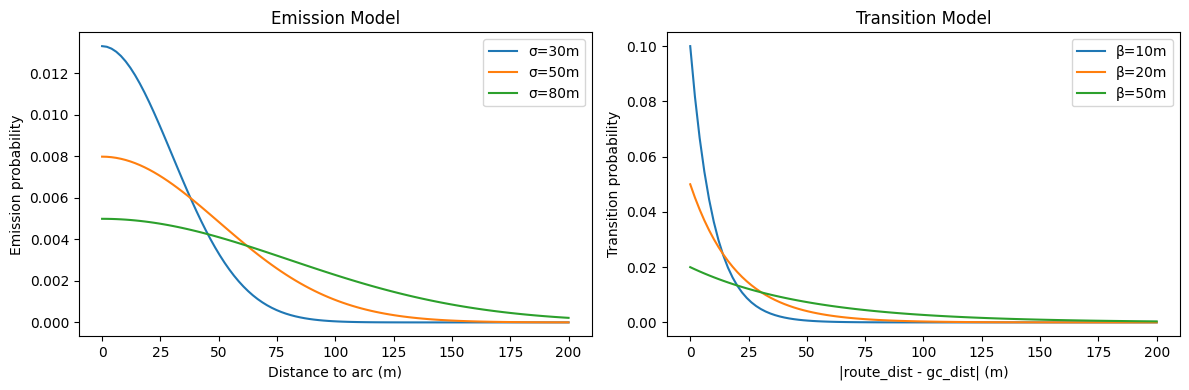

In [11]:
# Visualize emission probability
import matplotlib.pyplot as plt

dists = np.linspace(0, 200, 100)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for sigma in [30, 50, 80]:
    axes[0].plot(dists, [emission_prob(d, sigma) for d in dists], label=f'σ={sigma}m')
axes[0].set_xlabel('Distance to arc (m)')
axes[0].set_ylabel('Emission probability')
axes[0].set_title('Emission Model')
axes[0].legend()

dt_vals = np.linspace(0, 200, 100)
for beta in [10, 20, 50]:
    axes[1].plot(dt_vals, [transition_prob(d, 0, beta) for d in dt_vals], label=f'β={beta}m')
axes[1].set_xlabel('|route_dist - gc_dist| (m)')
axes[1].set_ylabel('Transition probability')
axes[1].set_title('Transition Model')
axes[1].legend()

plt.tight_layout()
plt.savefig('hmm_probability_models.png', dpi=100)
plt.show()

## 6. Viterbi Algorithm

In [12]:
def viterbi_decode(candidates_per_obs, track, nodes, arcs, graph,
                   sigma=50.0, beta=20.0, model_probs=None):
    """
    Viterbi decoding for map-matching.
    
    candidates_per_obs: list of [(arc_id, dist_m, proj_t), ...] per GPS point
    model_probs: optional dict (obs_idx, arc_id) -> ML classifier probability
    
    Returns: list of arc_ids (one per GPS observation)
    """
    T = len(candidates_per_obs)
    if T == 0:
        return []
    
    # Filter valid observations
    valid = [(i, c) for i, c in enumerate(candidates_per_obs) if len(c) > 0]
    if not valid:
        return [0] * T
    
    V = [{} for _ in range(len(valid))]
    bp = [{} for _ in range(len(valid))]
    
    # Init
    idx0, cands0 = valid[0]
    for arc_id, dist_m, _ in cands0:
        log_e = np.log(max(emission_prob(dist_m, sigma), 1e-300))
        if model_probs and (idx0, arc_id) in model_probs:
            log_e += np.log(max(model_probs[(idx0, arc_id)], 1e-300))
        V[0][arc_id] = log_e
        bp[0][arc_id] = None
    
    # Recurse
    for t in range(1, len(valid)):
        curr_idx, curr_cands = valid[t]
        prev_idx, prev_cands = valid[t-1]
        gc_dist = haversine(track[prev_idx,0], track[prev_idx,1],
                            track[curr_idx,0], track[curr_idx,1])
        
        for arc_c, dist_c, _ in curr_cands:
            log_e = np.log(max(emission_prob(dist_c, sigma), 1e-300))
            if model_probs and (curr_idx, arc_c) in model_probs:
                log_e += np.log(max(model_probs[(curr_idx, arc_c)], 1e-300))
            
            best_lp, best_prev = -np.inf, None
            for arc_p, _, _ in prev_cands:
                if arc_p not in V[t-1]:
                    continue
                rd = route_distance(arc_p, arc_c, arcs, graph)
                log_t = np.log(max(transition_prob(rd, gc_dist, beta), 1e-300))
                lp = V[t-1][arc_p] + log_t + log_e
                if lp > best_lp:
                    best_lp, best_prev = lp, arc_p
            
            if best_prev is not None:
                V[t][arc_c] = best_lp
                bp[t][arc_c] = best_prev
    
    # Backtrack
    if not V[-1]:
        return [c[0][0] if c else 0 for c in candidates_per_obs]
    
    best_last = max(V[-1], key=V[-1].get)
    decoded = [best_last]
    for t in range(len(valid)-1, 0, -1):
        prev = bp[t].get(decoded[-1])
        if prev is None:
            prev = valid[t-1][1][0][0] if valid[t-1][1] else 0
        decoded.append(prev)
    decoded.reverse()
    
    # Map back to all T observations
    result = [0] * T
    valid_idxs = [i for i, _ in valid]
    for i, vi in enumerate(valid_idxs):
        result[vi] = decoded[i]
    
    # Fill gaps
    for i in range(T):
        if not candidates_per_obs[i]:
            closest = min(valid_idxs, key=lambda j: abs(j-i))
            result[i] = result[closest]
    
    return result

In [13]:
def evaluate_route(predicted, ground_truth):
    """Accuracy and continuity metrics."""
    n = min(len(predicted), len(ground_truth))
    if n == 0:
        return {"accuracy": 0, "matched": 0, "total": 0, "continuity": 0}
    
    pred, gt = predicted[:n], ground_truth[:n]
    matches = sum(p == g for p, g in zip(pred, gt))
    
    # Continuity: consecutive predictions sharing a node
    contig = sum(1 for i in range(1, len(pred)) if pred[i] == pred[i-1])
    
    return {
        "accuracy": round(matches / n, 4),
        "matched": matches,
        "total": n,
        "continuity": round(contig / max(n-1, 1), 4)
    }

## 7. Run Viterbi on Sample Trip

In [14]:
# Run on first N points (full trip can be slow due to shortest-path queries)
N = 100  # increase once you confirm it works
test_track = trip["track"][:N]
test_cands = candidates[:N]
test_gt = trip["route"][:N].tolist()

t0 = time.time()
predicted = viterbi_decode(test_cands, test_track, trip["nodes"], trip["arcs"], graph,
                           sigma=50.0, beta=20.0)
elapsed = time.time() - t0

metrics = evaluate_route(predicted, test_gt)
print(f"Viterbi on {N} points: {elapsed:.1f}s")
print(f"Accuracy:   {metrics['accuracy']}  ({metrics['matched']}/{metrics['total']})")
print(f"Continuity: {metrics['continuity']}")

Viterbi on 100 points: 37.9s
Accuracy:   0.01  (1/100)
Continuity: 0.4242


In [15]:
# Compare: classifier-only (closest candidate) vs HMM
classifier_only = [c[0][0] if c else 0 for c in test_cands]
metrics_cls = evaluate_route(classifier_only, test_gt)

print("=== Classifier-only (closest arc) ===")
print(f"  Accuracy: {metrics_cls['accuracy']}  Continuity: {metrics_cls['continuity']}")
print("=== Classifier + HMM/Viterbi ===")
print(f"  Accuracy: {metrics['accuracy']}  Continuity: {metrics['continuity']}")
print(f"  Improvement: {metrics['accuracy'] - metrics_cls['accuracy']:+.4f} accuracy")

=== Classifier-only (closest arc) ===
  Accuracy: 0.01  Continuity: 0.5354
=== Classifier + HMM/Viterbi ===
  Accuracy: 0.01  Continuity: 0.4242
  Improvement: +0.0000 accuracy


## 8. Parameter Tuning
Try different sigma (emission) and beta (transition) values.

In [16]:
results = []
for sigma in [30, 50, 80, 100]:
    for beta in [10, 20, 50, 100]:
        pred = viterbi_decode(test_cands, test_track, trip["nodes"], trip["arcs"], graph,
                              sigma=sigma, beta=beta)
        m = evaluate_route(pred, test_gt)
        results.append({"sigma": sigma, "beta": beta, **m})
        print(f"σ={sigma:3d}  β={beta:3d}  acc={m['accuracy']:.4f}  cont={m['continuity']:.4f}")

results_df = pd.DataFrame(results).sort_values("accuracy", ascending=False)
print("\nTop 5:")
results_df.head()

σ= 30  β= 10  acc=0.0100  cont=0.4545
σ= 30  β= 20  acc=0.0100  cont=0.4545
σ= 30  β= 50  acc=0.0100  cont=0.4646
σ= 30  β=100  acc=0.0100  cont=0.5455
σ= 50  β= 10  acc=0.0100  cont=0.4040
σ= 50  β= 20  acc=0.0100  cont=0.4242
σ= 50  β= 50  acc=0.0100  cont=0.4545
σ= 50  β=100  acc=0.0100  cont=0.4646
σ= 80  β= 10  acc=0.0100  cont=0.4141
σ= 80  β= 20  acc=0.0100  cont=0.4040
σ= 80  β= 50  acc=0.0100  cont=0.4242
σ= 80  β=100  acc=0.0100  cont=0.4545
σ=100  β= 10  acc=0.0100  cont=0.4141
σ=100  β= 20  acc=0.0100  cont=0.4141
σ=100  β= 50  acc=0.0100  cont=0.4141
σ=100  β=100  acc=0.0100  cont=0.4444

Top 5:


,sigma,beta,accuracy,matched,total,continuity
0,30,10,0.01,1,100,0.4545
1,30,20,0.01,1,100,0.4545
2,30,50,0.01,1,100,0.4646
3,30,100,0.01,1,100,0.5455
4,50,10,0.01,1,100,0.4040


## 9. Folium Visualization

In [17]:
def make_map(trip, predicted_route, ground_truth=None, n_points=None):
    track = trip["track"][:n_points] if n_points else trip["track"]
    nodes, arcs = trip["nodes"], trip["arcs"]
    
    m = folium.Map(location=[np.mean(track[:,1]), np.mean(track[:,0])], zoom_start=14)
    
    # GPS points — blue
    gps_fg = folium.FeatureGroup(name="GPS Points (blue)")
    for i in range(len(track)):
        folium.CircleMarker([track[i,1], track[i,0]], radius=3,
                           color="blue", fill=True, fill_opacity=0.6).add_to(gps_fg)
    gps_fg.add_to(m)
    
    # Predicted route — red
    pred_fg = folium.FeatureGroup(name="Predicted Route (red)")
    for aid in predicted_route:
        if 0 <= aid < len(arcs):
            fn, tn = arcs[aid]
            folium.PolyLine([[nodes[fn,1], nodes[fn,0]], [nodes[tn,1], nodes[tn,0]]],
                           color="red", weight=4, opacity=0.8).add_to(pred_fg)
    pred_fg.add_to(m)
    
    # Ground truth — green
    if ground_truth is not None:
        gt_fg = folium.FeatureGroup(name="Ground Truth (green)")
        for aid in ground_truth:
            if 0 <= aid < len(arcs):
                fn, tn = arcs[aid]
                folium.PolyLine([[nodes[fn,1], nodes[fn,0]], [nodes[tn,1], nodes[tn,0]]],
                               color="green", weight=3, opacity=0.7).add_to(gt_fg)
        gt_fg.add_to(m)
    
    folium.LayerControl().add_to(m)
    return m

In [18]:
m = make_map(trip, predicted, ground_truth=test_gt, n_points=N)
m.save("trip_00000001_map.html")
print("Map saved to trip_00000001_map.html")
m  # displays inline in Jupyter

Map saved to trip_00000001_map.html


## 10. Test on Multiple Trips

In [19]:
# Run on a few training trips to validate
test_trip_ids = ["00000001", "00000002", "00000003", "00000004", "00000005"]
all_results = []

for tid in test_trip_ids:
    trip_path = os.path.join(TRAIN_DIR, tid)
    if not os.path.isdir(trip_path):
        continue
    t = load_trip(trip_path, tid)
    g = build_graph(t["nodes"], t["arcs"])
    
    n = min(100, len(t["track"]))  # first 100 points
    cands = generate_all_candidates(t["track"][:n], t["nodes"], t["arcs"], k=10)
    pred = viterbi_decode(cands, t["track"][:n], t["nodes"], t["arcs"], g)
    
    if t["route"] is not None:
        gt = t["route"][:n].tolist()
        m = evaluate_route(pred, gt)
        # Also get classifier-only baseline
        cls_pred = [c[0][0] if c else 0 for c in cands]
        m_cls = evaluate_route(cls_pred, gt)
        print(f"Trip {tid}: HMM acc={m['accuracy']:.4f}  baseline acc={m_cls['accuracy']:.4f}  "
              f"improvement={m['accuracy']-m_cls['accuracy']:+.4f}")
        all_results.append({"trip": tid, "hmm_acc": m["accuracy"], "baseline_acc": m_cls["accuracy"]})

if all_results:
    df = pd.DataFrame(all_results)
    print(f"\nMean HMM accuracy:      {df['hmm_acc'].mean():.4f}")
    print(f"Mean baseline accuracy: {df['baseline_acc'].mean():.4f}")

Trip 00000001: HMM acc=0.0100  baseline acc=0.0100  improvement=+0.0000
Trip 00000002: HMM acc=0.0000  baseline acc=0.0000  improvement=+0.0000
Trip 00000003: HMM acc=0.0127  baseline acc=0.0000  improvement=+0.0127
Trip 00000004: HMM acc=0.0300  baseline acc=0.0200  improvement=+0.0100
Trip 00000005: HMM acc=0.0100  baseline acc=0.0100  improvement=+0.0000

Mean HMM accuracy:      0.0125
Mean baseline accuracy: 0.0080


## 11. Export for API
Once you're happy with the parameters, the API files (`main.py`, `data_loader.py`, `road_network.py`, `hmm_viterbi.py`) in `backend/api/` are ready to go.

To start the server:
```
cd backend/api
python main.py
```
Then Laptop 2 hits: `http://<your-ip>:8000/predict/00000001`

In [20]:
# Save best parameters
best = results_df.iloc[0]
print(f"Best params: sigma={best['sigma']}, beta={best['beta']}, accuracy={best['accuracy']}")
print(f"\nUpdate these in backend/api/main.py:")
print(f"  SIGMA = {best['sigma']}")
print(f"  BETA = {best['beta']}")

Best params: sigma=30.0, beta=10.0, accuracy=0.01

Update these in backend/api/main.py:
  SIGMA = 30.0
  BETA = 10.0
